## Лабораторная работа №1 | Вариант 6

Выполнил: Кретов Александр Владимирович, М8О-313БВ-24 

### 1. Numpy

In [1]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [2]:
identity = np.eye(3, dtype=int)
identity

array([[1, 0, 0],
       [0, 1, 0],
       [0, 0, 1]])

2. Создайте матрицу 5х5 со значениями 1, 2, 3, 4 ниже диагонали

In [3]:
subdiagonal = np.diag([1, 2, 3, 4], k=-1)
subdiagonal

array([[0, 0, 0, 0, 0],
       [1, 0, 0, 0, 0],
       [0, 2, 0, 0, 0],
       [0, 0, 3, 0, 0],
       [0, 0, 0, 4, 0]])

3. Какой выход будет у данного скрипта

```python
# Author: Jake VanderPlas

print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))
```

In [4]:
print(sum(range(5), -1)) # встроенная sum даст 9, а из np - 10
print(np.sum(range(5), -1))

9
10


4. Как найти самое часто встречаемое значение между двумя массивами? 

In [5]:
a = np.array([1, 2, 2, 3, 5])
b = np.array([2, 3, 3, 4, 5])
values, counts = np.unique(np.concatenate([a, b]), return_counts=True)
modes = values[counts == counts.max()]
print('Все моды объединённой выборки:', modes)
print('Число вхождений каждой моды:', counts.max())

Все моды объединённой выборки: [2 3]
Число вхождений каждой моды: 3


5. Как игнорировать все warnings в numpy(не нужно так делать, но покажи)?

In [6]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    with np.errstate(all='ignore'):
        result = np.array([1.0, 0.0]) / 0.0
        print(result)

[inf nan]


6. Реализуем функцию-генератор, которая генерирует 10 целых чисел и используем ее для построения массива

In [7]:
def integer_generator():
    for number in range(10):
        yield number

generated = np.fromiter(integer_generator(), dtype=np.int64, count=10)
generated

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

7. Создайте массив случайных чисел размером 10 и отсортируйте его

In [8]:
rng = np.random.default_rng(42)
random_values = rng.random(10)
print('Исходный массив:', random_values)
print('Отсортированный:', np.sort(random_values))

Исходный массив: [0.77395605 0.43887844 0.85859792 0.69736803 0.09417735 0.97562235
 0.7611397  0.78606431 0.12811363 0.45038594]
Отсортированный: [0.09417735 0.12811363 0.43887844 0.45038594 0.69736803 0.7611397
 0.77395605 0.78606431 0.85859792 0.97562235]


8. Создайте случайную матрицу 10х2 которая представляет собой декартовые координаты и преобразуйте их в полярные

In [9]:
rng = np.random.default_rng(43)
cartesian = rng.uniform(-10, 10, size=(10, 2))
x, y = cartesian.T
radius = np.hypot(x, y)
angle = np.arctan2(y, x)
polar = np.column_stack([radius, angle])
print('Декартовы координаты (x, y):\n', cartesian)
print('Полярные координаты (r, угол в радианах):\n', polar)

Декартовы координаты (x, y):
 [[ 3.04598525 -9.12449353]
 [-9.59940826  6.78425165]
 [ 1.74286095 -5.5058954 ]
 [ 5.03584544 -4.72615605]
 [-1.60044181 -0.97937226]
 [ 9.10629158  7.83803338]
 [-4.42733949 -4.42931404]
 [-1.5600085  -9.9184455 ]
 [-3.82152465  9.03508033]
 [ 6.76409557  0.70256514]]
Полярные координаты (r, угол в радианах):
 [[ 9.61948067 -1.24860322]
 [11.7547739   2.52635988]
 [ 5.77515787 -1.26423104]
 [ 6.90625009 -0.75368484]
 [ 1.87632193 -2.59244092]
 [12.01496208  0.71068892]
 [ 6.26259993 -2.35597154]
 [10.04037786 -1.72680185]
 [ 9.81003197  1.97094223]
 [ 6.80048429  0.10349571]]


9. Создайте структурированный массив который будет описывать пиксель(координату x, y и цвет r,g,b)

In [10]:
pixel_dtype = np.dtype([
    ('x', np.int32), ('y', np.int32),
    ('r', np.uint8), ('g', np.uint8), ('b', np.uint8),
])
pixels = np.array([(10, 20, 255, 0, 0), (30, 40, 0, 128, 255)], dtype=pixel_dtype)
print(pixels)
print('Красная компонента:', pixels['r'])

[(10, 20, 255,   0,   0) (30, 40,   0, 128, 255)]
Красная компонента: [255   0]


10. Как конвертировать тип массив от float32 в int32 in place?

In [11]:
floats = np.array([1.9, -2.7, 3.0, 0.0], dtype=np.float32)
address_before = floats.ctypes.data
print('До преобразования:', floats, floats.dtype)
# float32 и int32 равны о размеру
integers = floats.view(np.int32)
for i in range(floats.size):
    integers[i] = int(floats[i])
floats = integers
print('После преобразования:', floats, floats.dtype)
print('Адрес буфера сохранён:', floats.ctypes.data == address_before)

До преобразования: [ 1.9 -2.7  3.   0. ] float32
После преобразования: [ 1 -2  3  0] int32
Адрес буфера сохранён: True


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Набор данных описывает эффективность учеников в зависимости от некоторых факторов влияющих на обучение и окружение человека.

Файл: `student_perfomance.csv`

```
Hours_Studied - количество часов затраченное на обучение в неделю
Attendance - поцент посещенных занятий
Parental_Involvement - уровень участия родителей в обучении учащегося
Access_to_Resources - доступность ресурсов для обучения
Extracurricular_Activities - участие во внеклассных мероприятиях
Sleep_Hours - количество часов выделяемое на сон в день
Previous_Scores - оценка за первый экзамен
Motivation_Level - уровень мотивации
Internet_Access - доступ к интернету
Tutoring_Sessions - количество посещаемых репетиторских занятий в месяц.
Family_Income - доход семьи
Teacher_Quality - насколько качественно преподает учитель
School_Type - тип школы(частная, обычная)
Peer_Influence - влияние сверстников
Physical_Activity - физическая активность
Learning_Disabilities - наличие проблем с обучаемостью
Parental_Education_Level - уровень образования родителей
Distance_from_Home - дистанция от дома до школы
Gender - пол
Exam_Score - оценка на конечном экзамене
```

In [19]:
import pandas as pd
from pathlib import Path
from IPython.display import display

In [20]:
df = pd.read_csv("student_perfomance.csv")
df

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


1. Посчитайте среднее кол-во часов уделяемое на сон студентами

In [21]:
mean_sleep = df['Sleep_Hours'].mean()
print(f'Средний сон: {mean_sleep:.4f} часа в день')

Средний сон: 7.0291 часа в день


2. Сколько процентов студентов посещают внеклассовые активности?

In [22]:
activity_percent = df["Extracurricular_Activities"].eq("Yes").mean() * 100
print(f"Доля студентов, участвующих во внеклассных занятиях: {activity_percent:.2f}%")

Доля студентов, участвующих во внеклассных занятиях: 59.60%


3. Правда ли, что в среднем девушки сдают экзамены лучше, чем мужчины

In [23]:
gender_stats = df.groupby('Gender')[['Previous_Scores', 'Exam_Score']].agg(['count', 'mean'])
display(gender_stats)
gender_means = df.groupby('Gender')['Exam_Score'].mean()
gender_difference = gender_means['Female'] - gender_means['Male']
print(f'Разница итоговых баллов (Female − Male): {gender_difference:.4f}')

if gender_means["Female"] > gender_means["Male"]:
    print("Да, в этой выборке средний балл девушек выше, чем у юношей.")
else:
    print("Нет, в этой выборке средний балл девушек не выше, чем у юношей.")

Previous_Scores            Exam_Score           
                 count       mean      count       mean
Gender                                                 
Female            2793  75.053348       2793  67.244898
Male              3814  75.083115       3814  67.228894

Разница итоговых баллов (Female − Male): 0.0160
Да, в этой выборке средний балл девушек выше, чем у юношей.


Но разница незначительна

4. Выведите 25 и 75 перцентили времени сна студентов

In [24]:
q25, q75 = df['Sleep_Hours'].quantile([0.25, 0.75])
print(f'25-й перцентиль: {q25:g} часов')
print(f'75-й перцентиль: {q75:g} часов')

25-й перцентиль: 6 часов
75-й перцентиль: 8 часов


5. Правда ли, что те, кто спит больше(75 перцентиль и выше) сдает экзамен лучше, чем студенты с недосыпом(25 перцентиль и меньше)

In [25]:
short_sleep = df.loc[df['Sleep_Hours'].le(q25), 'Exam_Score']
long_sleep = df.loc[df['Sleep_Hours'].ge(q75), 'Exam_Score']
sleep_comparison = pd.DataFrame({
    'Группа': [f'Сон ≤ {q25:g} ч', f'Сон ≥ {q75:g} ч'],
    'Число студентов': [short_sleep.count(), long_sleep.count()],
    'Средний балл': [short_sleep.mean(), long_sleep.mean()],
}).set_index('Группа')
display(sleep_comparison)
print(f'Разница (долгий − короткий сон): {long_sleep.mean()-short_sleep.mean():.4f}')

,Число студентов,Средний балл
Группа,,
Сон ≤ 6 ч,2380,67.281092
Сон ≥ 8 ч,2486,67.187047


Разница (долгий − короткий сон): -0.0940


Нет, в этой выборке это неправда: при сне не менее 8 часов средний балл чуть ниже, чем у студентов с недосыпом

6. Влияет ли физическая активность на результаты экзамена?

In [26]:
physical_stats = df.groupby('Physical_Activity')['Exam_Score'].agg(['count', 'mean', 'median'])
physical_corr = df['Physical_Activity'].corr(df['Exam_Score'])
display(physical_stats)
print(f'Корреляция Пирсона: {physical_corr:.4f}')

,count,mean,median
Physical_Activity,,,
0,46,67.521739,68.0
1,421,66.969121,67.0
2,1627,67.185003,67.0
3,2545,67.196071,67.0
4,1575,67.313016,67.0
5,361,67.603878,67.0
6,32,68.093750,68.0


Корреляция Пирсона: 0.0278


Линейная связь практически отсутствует

7. Правда ли, что слуденты, чьи родители имеют высшее образование(College || Postgraduate), сдают экзамены лучше, чем остальные?

In [27]:
education = df.dropna(subset=['Parental_Education_Level', 'Exam_Score']).copy()
education['Higher_Education'] = education['Parental_Education_Level'].isin(['College', 'Postgraduate'])
education_stats = education.groupby('Higher_Education')['Exam_Score'].agg(['count', 'mean'])
display(education_stats.rename(index={False: 'High School', True: 'College или Postgraduate'}))
education_difference = education_stats.loc[True, 'mean'] - education_stats.loc[False, 'mean']
print(f'Разница средних: {education_difference:.4f} балла')
print('Исключено строк с неизвестным образованием родителей:', len(df)-len(education))

,count,mean
Higher_Education,,
High School,3223,66.893577
College или Postgraduate,3294,67.575288


Разница средних: 0.6817 балла
Исключено строк с неизвестным образованием родителей: 90


На данной выборке - да, правда. Средний балл у группы с высшим образованием родителей выше

8. Как влияет участие родителей на результаты экзаменов

In [28]:
involvement_stats = df.groupby('Parental_Involvement')['Exam_Score'].agg(['count', 'mean', 'median']).reindex(['Low', 'Medium', 'High'])
display(involvement_stats)
print(f"High − Low: {involvement_stats.loc['High', 'mean']-involvement_stats.loc['Low', 'mean']:.4f} балла")

,count,mean,median
Parental_Involvement,,,
Low,1337,66.358265,66.0
Medium,3362,67.098156,67.0
High,1908,68.092767,68.0


High − Low: 1.7345 балла


Средние баллы возрастают с уровнем участия родителей

9. Правда ли, что в семьях с доходом больше среднего дети сдают экзамены лучше?

In [29]:
income_stats = df.groupby('Family_Income')['Exam_Score'].agg(['count', 'mean']).reindex(['Low', 'Medium', 'High'])
display(income_stats)
high_income = df.loc[df['Family_Income'].eq('High'), 'Exam_Score']
other_income = df.loc[df['Family_Income'].isin(['Low', 'Medium']), 'Exam_Score']
print(f'High: {high_income.mean():.4f}; Low и Medium вместе: {other_income.mean():.4f}')
print(f'Разница: {high_income.mean()-other_income.mean():.4f} балла')

,count,mean
Family_Income,,
Low,2672,66.848428
Medium,2666,67.334959
High,1269,67.842396


High: 67.8424; Low и Medium вместе: 67.0914
Разница: 0.7510 балла


В этой выборке - да: средний балл High равен 67,8424, что выше среднего каждой из категорий Low и Medium, а также их объединения

10. Посчитайте долю студентов сдавших экзамен на более чем 70 баллов в семьях с низким доходом и отсутствием доступа к интернету

In [30]:
income_internet_mask = df['Family_Income'].eq('Low') & df['Internet_Access'].eq('No')
target_group = df.loc[income_internet_mask, 'Exam_Score'].dropna()
passed_count = target_group.gt(70).sum()
share = target_group.gt(70).mean()
print(f'Более 70 баллов: {passed_count} из {len(target_group)}')
print(f'Доля внутри указанной группы: {share:.6f} ({share:.2%})')

Более 70 баллов: 17 из 211
Доля внутри указанной группы: 0.080569 (8.06%)


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Правда ли, что количество часов затрачиваемых на сон распределено примерно нормально?

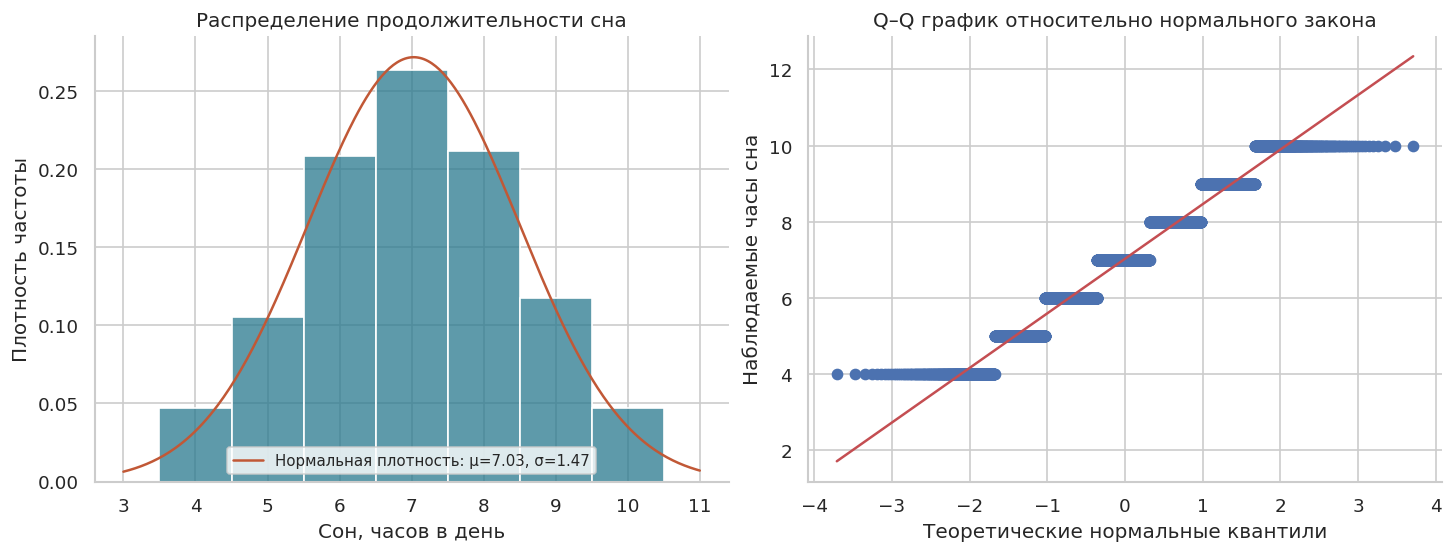

Среднее: 7.0291; медиана: 7.0; асимметрия: -0.0238


In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style='whitegrid', context='notebook', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False})

sleep = df['Sleep_Hours'].dropna()
mu, sigma = sleep.mean(), sleep.std(ddof=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
sns.histplot(sleep, bins=np.arange(3.5, 11.5, 1), stat='density',
             color='#28788E', ax=axes[0])
grid = np.linspace(3, 11, 300)
axes[0].plot(grid, stats.norm.pdf(grid, mu, sigma), color='#C15836',
             label=f'Нормальная плотность: μ={mu:.2f}, σ={sigma:.2f}')
axes[0].set(title='Распределение продолжительности сна',
            xlabel='Сон, часов в день', ylabel='Плотность частоты')
axes[0].legend(fontsize=9)
stats.probplot(sleep, dist='norm', plot=axes[1])
axes[1].set(title='Q–Q график относительно нормального закона',
            xlabel='Теоретические нормальные квантили',
            ylabel='Наблюдаемые часы сна')
plt.show()
print(f'Среднее: {mu:.4f}; медиана: {sleep.median():.1f}; '
      f'асимметрия: {sleep.skew():.4f}')

Распределение по форме близко к нормальному, однако значения дискретны и ограничены, поэтому точным нормальным распределением его считать нельзя.

2. Постройте гистограмму распределения количества часов затрачиваемых на обучение среди мальчиков и девочек

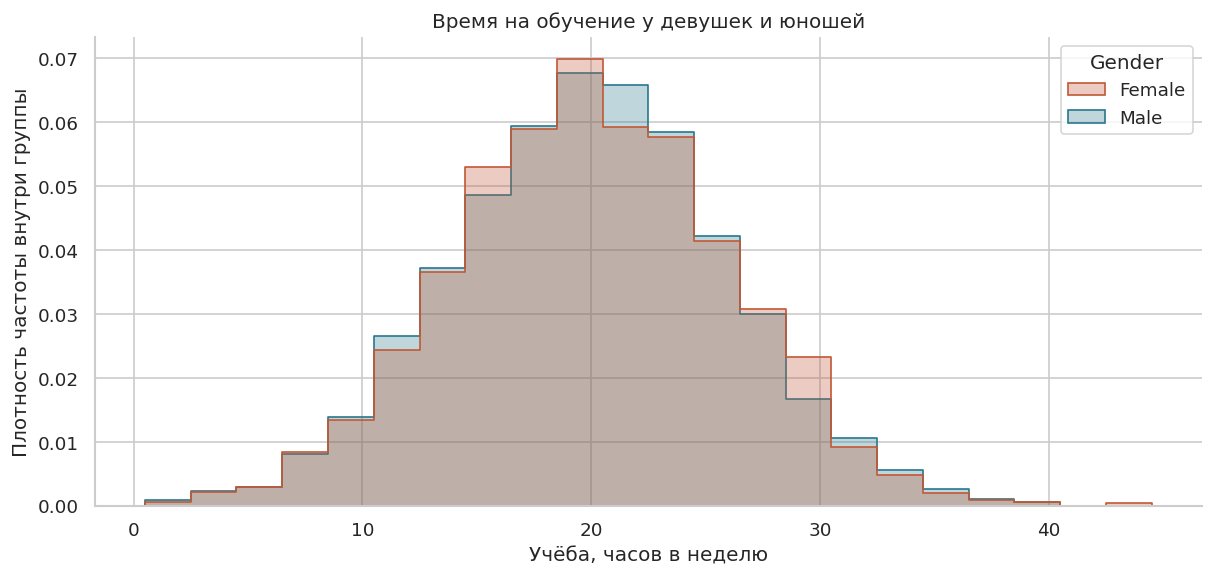

,count,mean,median,std
Gender,,,,
Female,2793,20.005013,20.0,5.997251
Male,3814,19.953592,20.0,5.986408


In [32]:
fig, ax = plt.subplots(figsize=(10, 4.7), layout='constrained')
sns.histplot(data=df, x='Hours_Studied', hue='Gender', hue_order=['Female', 'Male'],
             bins=np.arange(0.5, 45.5, 2), stat='density', common_norm=False,
             element='step', alpha=0.3, palette=['#C15836', '#28788E'], ax=ax)
ax.set(title='Время на обучение у девушек и юношей',
       xlabel='Учёба, часов в неделю', ylabel='Плотность частоты внутри группы')
plt.show()
display(df.groupby('Gender')['Hours_Studied'].agg(['count', 'mean', 'median', 'std']))

3. Как зависит результат конечного экзамена от результата первого экзамена

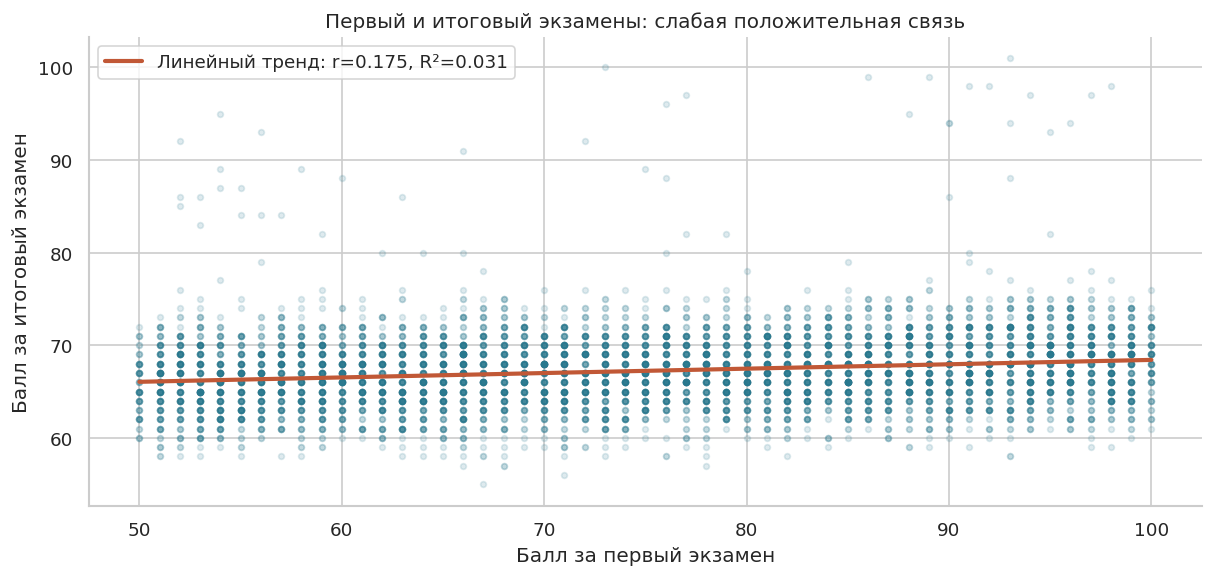

Exam_Score ≈ 63.6847 + 0.0473 × Previous_Scores
r = 0.1751; R² на этих же данных = 0.0307


In [33]:
previous = df[['Previous_Scores', 'Exam_Score']].dropna()
x_prev = previous['Previous_Scores'].to_numpy()
y_final = previous['Exam_Score'].to_numpy()
design = np.column_stack([np.ones(len(previous)), x_prev])
intercept, slope = np.linalg.lstsq(design, y_final, rcond=None)[0]
predictions = design @ np.array([intercept, slope])
previous_r = previous['Previous_Scores'].corr(previous['Exam_Score'])
r_squared = 1 - np.sum((y_final-predictions)**2) / np.sum((y_final-y_final.mean())**2)

fig, ax = plt.subplots(figsize=(10, 4.7), layout='constrained')
ax.scatter(x_prev, y_final, s=12, alpha=0.15, color='#28788E', rasterized=True)
line_x = np.array([x_prev.min(), x_prev.max()])
ax.plot(line_x, intercept+slope*line_x, color='#C15836', linewidth=2.5,
        label=f'Линейный тренд: r={previous_r:.3f}, R²={r_squared:.3f}')
ax.set(title='Первый и итоговый экзамены: слабая положительная связь',
       xlabel='Балл за первый экзамен', ylabel='Балл за итоговый экзамен')
ax.legend()
plt.show()
print(f'Exam_Score ≈ {intercept:.4f} + {slope:.4f} × Previous_Scores')
print(f'r = {previous_r:.4f}; R² на этих же данных = {r_squared:.4f}')

Наблюдается слабая положительная связь: более высоким оценкам за первый экзамен в среднем соответствуют более высокие итоговые оценки.

4. Постройте box plot отображающий распределение количества сна детей сдавших экзамены на оценку ниже и выше 85 баллов

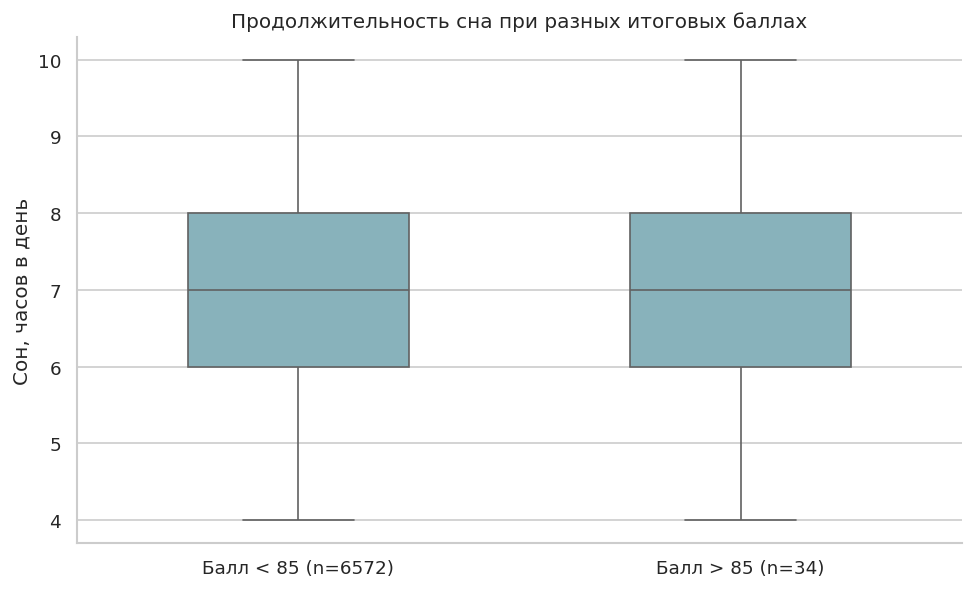

,count,mean,median
Группа,,,
Балл < 85,6572,7.029519,7.0
Балл > 85,34,6.882353,7.0


Не входят в строгие группы (балл = 85): 1


In [34]:
box_data = df.loc[df['Exam_Score'].lt(85) | df['Exam_Score'].gt(85),
                  ['Sleep_Hours', 'Exam_Score']].copy()
box_data['Группа'] = np.where(box_data['Exam_Score'].lt(85), 'Балл < 85', 'Балл > 85')
box_order = ['Балл < 85', 'Балл > 85']
fig, ax = plt.subplots(figsize=(8, 4.8), layout='constrained')
sns.boxplot(data=box_data, x='Группа', y='Sleep_Hours', order=box_order,
            color='#7FB7C4', width=0.5, ax=ax)
counts = box_data['Группа'].value_counts()
ax.set_xticks(range(2), [f'{label} (n={counts[label]})' for label in box_order])
ax.set(title='Продолжительность сна при разных итоговых баллах',
       xlabel='', ylabel='Сон, часов в день')
plt.show()
display(box_data.groupby('Группа')['Sleep_Hours'].agg(['count', 'mean', 'median']))
print('Не входят в строгие группы (балл = 85):', df['Exam_Score'].eq(85).sum())

5. Правда ли, что количество посещаемых занятий с репетитором в месяц напрямую влияет на балл в конечном экзамене?

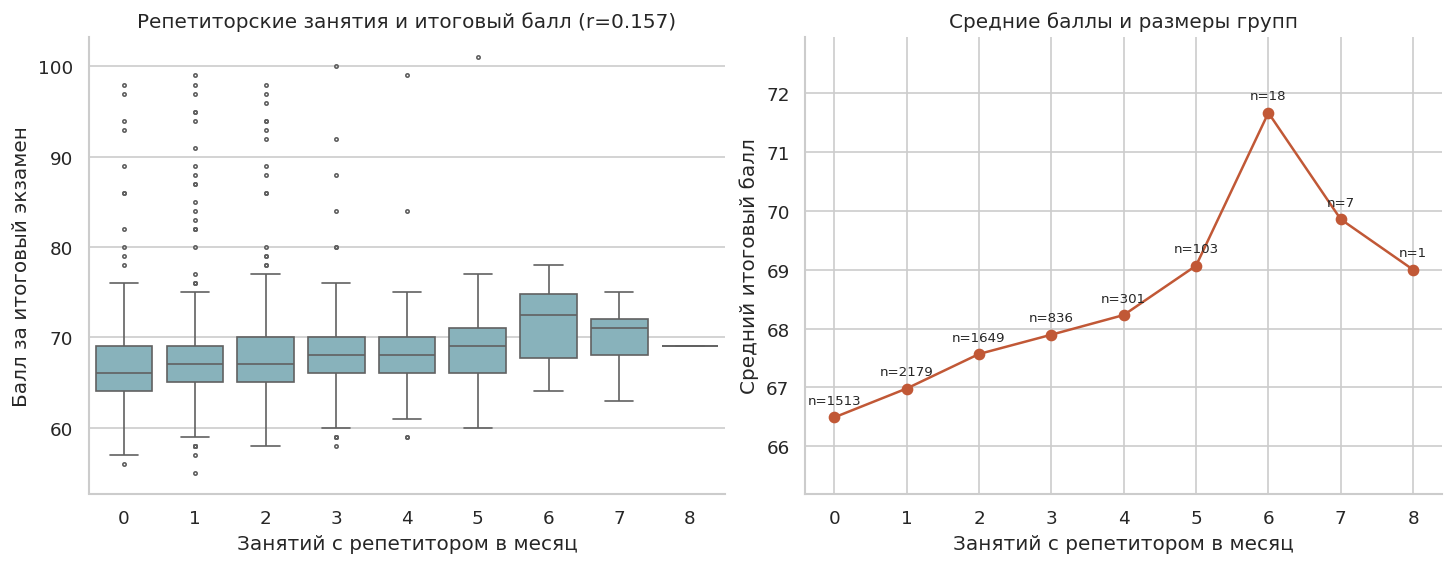

,count,mean,median
Tutoring_Sessions,,,
0,1513,66.489755,66.0
1,2179,66.980266,67.0
2,1649,67.567010,67.0
3,836,67.894737,68.0
4,301,68.229236,68.0
5,103,69.067961,69.0
6,18,71.666667,72.5
7,7,69.857143,71.0
8,1,69.000000,69.0


In [35]:
tutoring_stats = df.groupby('Tutoring_Sessions')['Exam_Score'].agg(['count', 'mean', 'median'])
tutoring_r = df['Tutoring_Sessions'].corr(df['Exam_Score'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained')
sns.boxplot(data=df, x='Tutoring_Sessions', y='Exam_Score', color='#7FB7C4',
            fliersize=2, ax=axes[0])
axes[0].set(title=f'Репетиторские занятия и итоговый балл (r={tutoring_r:.3f})',
            xlabel='Занятий с репетитором в месяц', ylabel='Балл за итоговый экзамен')
axes[1].plot(tutoring_stats.index, tutoring_stats['mean'], 'o-', color='#C15836')
for session, row in tutoring_stats.iterrows():
    axes[1].annotate(f"n={int(row['count'])}", (session, row['mean']),
                     xytext=(0, 8), textcoords='offset points', ha='center', fontsize=8)
axes[1].margins(y=0.25)
axes[1].set(title='Средние баллы и размеры групп',
            xlabel='Занятий с репетитором в месяц', ylabel='Средний итоговый балл')
plt.show()
display(tutoring_stats)

Наблюдается слабая положительная связь между количеством занятий и итоговым баллом. Однако данные не доказывают прямого влияния занятий на результат.

6. Как физическая активность влияет на успеваемость?

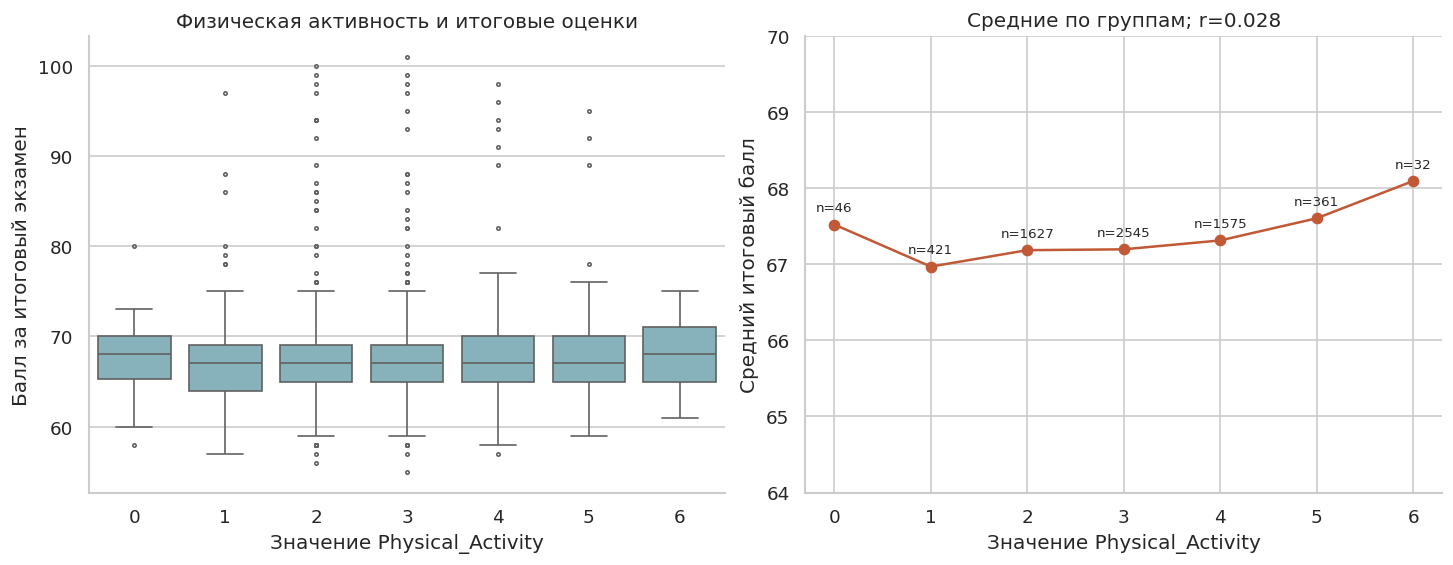

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained')
sns.boxplot(data=df, x='Physical_Activity', y='Exam_Score',
            color='#7FB7C4', fliersize=2, ax=axes[0])
axes[0].set(title='Физическая активность и итоговые оценки',
            xlabel='Значение Physical_Activity', ylabel='Балл за итоговый экзамен')
axes[1].plot(physical_stats.index, physical_stats['mean'], 'o-', color='#C15836')
for value, row in physical_stats.iterrows():
    axes[1].annotate(f"n={int(row['count'])}", (value, row['mean']),
                     xytext=(0, 8), textcoords='offset points', ha='center', fontsize=8)
axes[1].set_ylim(64, 70)
axes[1].set(title=f'Средние по группам; r={physical_corr:.3f}',
            xlabel='Значение Physical_Activity', ylabel='Средний итоговый балл')
plt.show()

Выраженной линейной связи физической активности с итоговым баллом не обнаружено. Делать вывод о причинном влиянии по этим данным нельзя.

7. Постройте HeatMap где ось Х - процент посещаемость, Y - количество занятий с репетитором, а Z - балл за итоговый экзамен*

\* Задание на доп. балл

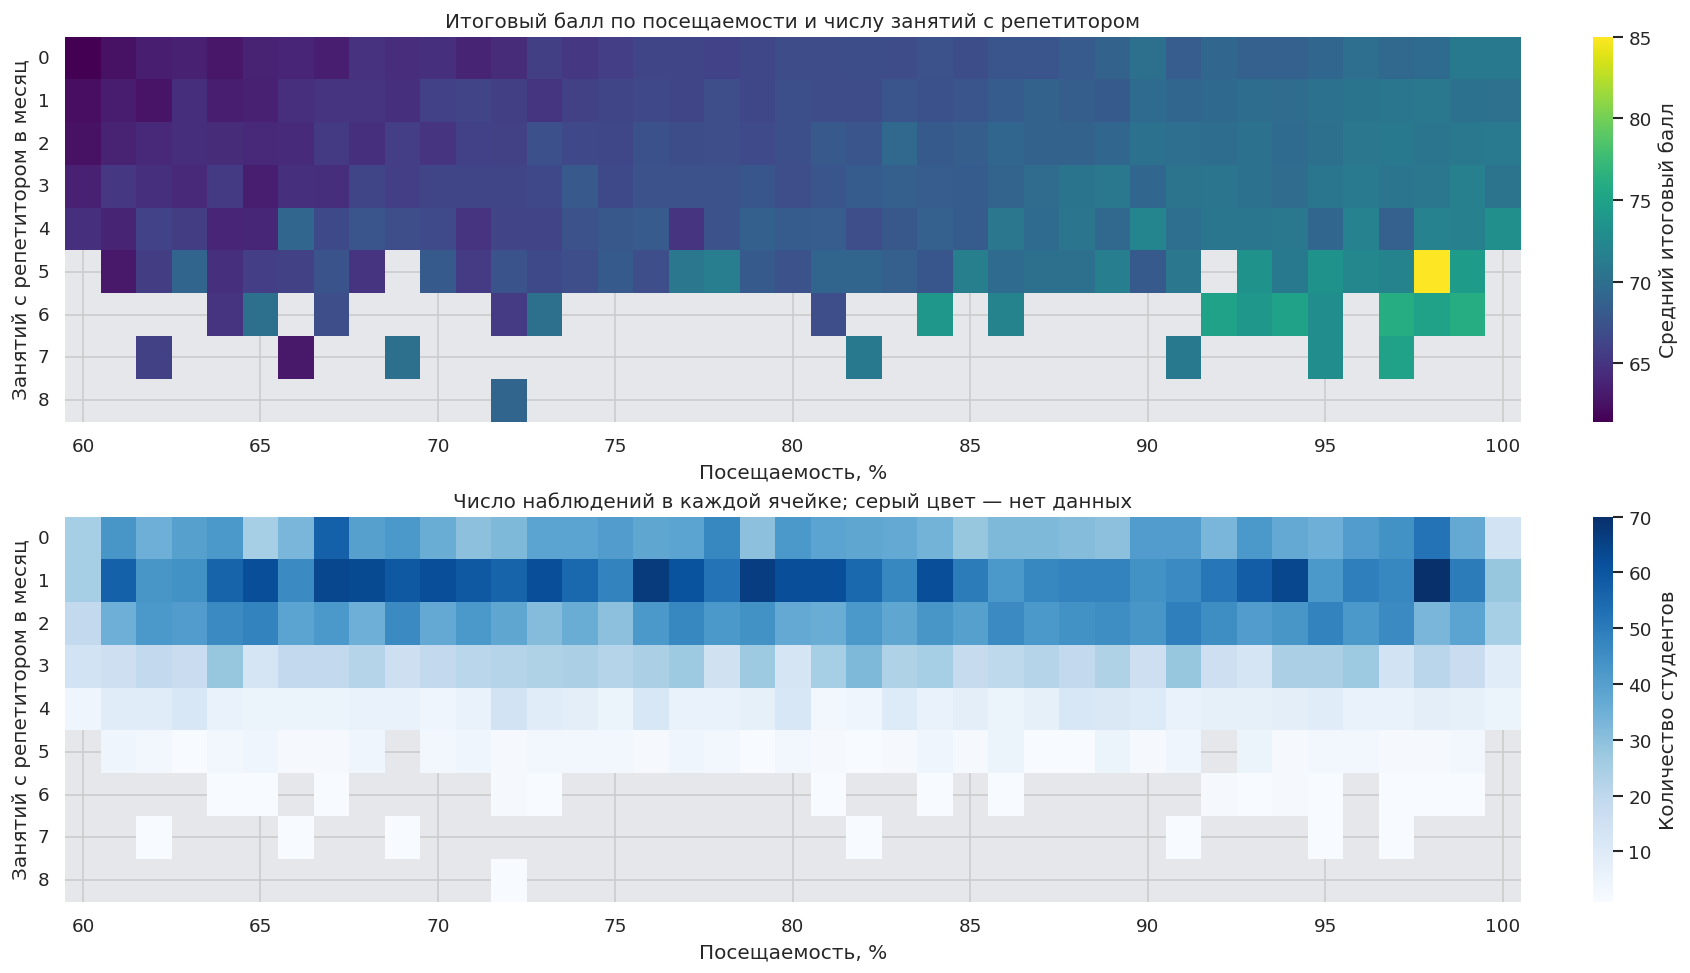

Учтено наблюдений: 6607


In [37]:
heat_mean = df.pivot_table(index='Tutoring_Sessions', columns='Attendance',
                           values='Exam_Score', aggfunc='mean').sort_index().sort_index(axis=1)
heat_count = df.pivot_table(index='Tutoring_Sessions', columns='Attendance',
                            values='Exam_Score', aggfunc='count').reindex_like(heat_mean)
fig, axes = plt.subplots(2, 1, figsize=(14, 8), layout='constrained')
sns.heatmap(heat_mean, mask=heat_mean.isna(), cmap='viridis',
            xticklabels=5, yticklabels=1, cbar_kws={'label': 'Средний итоговый балл'}, ax=axes[0])
sns.heatmap(heat_count, mask=heat_count.isna(), cmap='Blues',
            xticklabels=5, yticklabels=1, cbar_kws={'label': 'Количество студентов'}, ax=axes[1])
for ax in axes:
    ax.set_facecolor('#E5E7EB')
    ax.set(xlabel='Посещаемость, %', ylabel='Занятий с репетитором в месяц')
    ax.tick_params(axis='y', rotation=0)
axes[0].set_title('Итоговый балл по посещаемости и числу занятий с репетитором')
axes[1].set_title('Число наблюдений в каждой ячейке; серый цвет — нет данных')
plt.show()
print('Учтено наблюдений:', int(heat_count.sum().sum()))